# <span style="color:darkblue"> Lecture 15b: Time Series Cross-Validation </span>


# <span style="color:darkblue"> I. Setup Working Environment </span>


<font size = "5">

Import data from Introduction to Statistical Learning

In [1]:
from ISLP import load_data
from ISLP.models import summarize

<font size = "5">

Import standard packages

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm


<font size = "5">

Import SK-learn packages


In [3]:
# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn import preprocessing

# <span style="color:darkblue"> II. Data </span>


<font size = "5">

Import data from Introduction to Statistical Learning

- This is time series data
- It is sorted from earlier time periods to later time periods

In [4]:
Smarket = load_data('Smarket')
Smarket

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
0,2001,0.381,-0.192,-2.624,-1.055,5.010,1.19130,0.959,Up
1,2001,0.959,0.381,-0.192,-2.624,-1.055,1.29650,1.032,Up
2,2001,1.032,0.959,0.381,-0.192,-2.624,1.41120,-0.623,Down
3,2001,-0.623,1.032,0.959,0.381,-0.192,1.27600,0.614,Up
4,2001,0.614,-0.623,1.032,0.959,0.381,1.20570,0.213,Up
...,...,...,...,...,...,...,...,...,...
1245,2005,0.422,0.252,-0.024,-0.584,-0.285,1.88850,0.043,Up
1246,2005,0.043,0.422,0.252,-0.024,-0.584,1.28581,-0.955,Down
1247,2005,-0.955,0.043,0.422,0.252,-0.024,1.54047,0.130,Up
1248,2005,0.130,-0.955,0.043,0.422,0.252,1.42236,-0.298,Down


<Axes: >

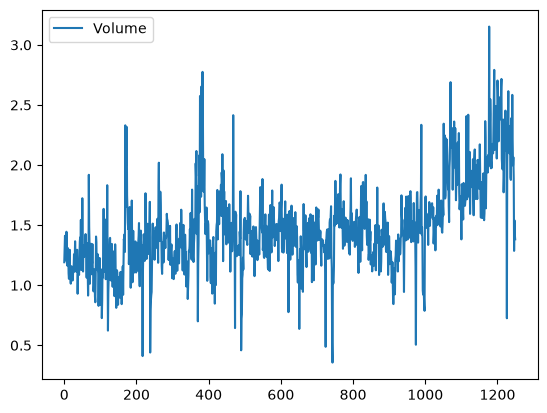

In [5]:
Smarket.plot(y='Volume')

# <span style="color:darkblue"> III. Expanding window cross-validation </span>

<font size = "5">

Try it yourself!

In this exercise you will code up your own time series <br>
cross-validation algorith:


<font size = "3">

PART I:


- Create an index for observation number
- Split the data in half. However, do not do it at random, <br>
instead set the training data to be the first set of observations
- Train an Decision Tree model on the first half.
- Test how well it does on the next observations in terms of MSE.

PART II:
- Now construct a training dataset that includes half + one more observation
- Train the Decision Tree and check its performance in terms of MSE.

PART III:
- Create a loop that repeats this process 10 more times, adding <br>
one more observation to the training set each time.

This is expanding window cross-validation!







In [ ]:
# Write your own code




import pandas as pd
import numpy as np

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

# Use the dataset already loaded in the notebook
df = Smarket

# Examine the first five rows
df.head()




,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
0,2001,0.381,-0.192,-2.624,-1.055,5.010,1.1913,0.959,Up
1,2001,0.959,0.381,-0.192,-2.624,-1.055,1.2965,1.032,Up
2,2001,1.032,0.959,0.381,-0.192,-2.624,1.4112,-0.623,Down
3,2001,-0.623,1.032,0.959,0.381,-0.192,1.2760,0.614,Up
4,2001,0.614,-0.623,1.032,0.959,0.381,1.2057,0.213,Up


In [10]:

# Create an observation index
df = df.reset_index(drop=True)
df["observation"] = np.arange(1, len(df) + 1)

# Find the halfway point
half = len(df) // 2

# First half for training
train = df.iloc[:half].copy()

# Next observation for testing
test = df.iloc[half:half+1].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))


Training observations: 625
Testing observations: 1


In [15]:

# Select the outcome variable
target = "your_target_column"

# Separate predictors (X) and outcome (y)
X_train = train.drop(columns=[target, "observation"])
y_train = train[target]

X_test = test.drop(columns=[target, "observation"])
y_test = test[target]

# Create and train Decision Tree
model = DecisionTreeRegressor(random_state=42)
model.fit(X_train, y_train)

# Predict the next observation
y_pred = model.predict(X_test)

# Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

print("Actual value:", y_test.values)
print("Predicted value:", y_pred)
print("MSE:", mse)
print(df.columns.tolist())


KeyError: "['your_target_column'] not found in axis"

In [ ]:

import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

# ---------------------------------
# STEP 1: Prepare the dataset
# ---------------------------------

df = df.copy()

# Display available columns
print("Available columns:")
print(df.columns.tolist())

# Enter the column you want to predict
target = input("Enter the outcome column name: ").strip()

if target not in df.columns:
    raise ValueError("Target column not found. Check the column name.")

# Keep observations in their original time order
df = df.reset_index(drop=True)

# Create observation index
df["observation"] = np.arange(1, len(df) + 1)

# Select predictors and outcome
X = df.drop(columns=[target, "observation"])
y = df[target]

# Convert categorical predictors into numeric columns
X = pd.get_dummies(X, dummy_na=True)

# Fill missing predictor values
X = X.fillna(X.median()).fillna(0)

# Check outcome values
if y.isna().any():
    raise ValueError("The outcome column contains missing values.")

# ---------------------------------
# PART I: Initial training window
# ---------------------------------

half = len(df) // 2

if len(df) < 24:
    raise ValueError("At least 24 observations are needed for all 12 tests.")

X_train = X.iloc[:half]
y_train = y.iloc[:half]

X_test = X.iloc[half:half+1]
y_test = y.iloc[half:half+1]

model = DecisionTreeRegressor(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)

print("\nPART I")
print("Training observations:", len(X_train))
print("Actual value:", y_test.values)
print("Predicted value:", y_pred)
print("MSE:", mse)



Available columns:
['Year', 'Lag1', 'Lag2', 'Lag3', 'Lag4', 'Lag5', 'Volume', 'Today', 'Direction', 'observation']


In [ ]:
# ---------------------------------
# PART II: Expand by one observation
# ---------------------------------

X_train = X.iloc[:half+1]
y_train = y.iloc[:half+1]

X_test = X.iloc[half+1:half+2]
y_test = y.iloc[half+1:half+2]

model = DecisionTreeRegressor(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)

print("\nPART II")
print("Training observations:", len(X_train))
print("Actual value:", y_test.values)
print("Predicted value:", y_pred)
print("MSE:", mse)



In [ ]:
# ---------------------------------
# PART III: Repeat 10 more times
# ---------------------------------

results = []

for i in range(10):

    train_end = half + 2 + i

    X_train = X.iloc[:train_end]
    y_train = y.iloc[:train_end]

    X_test = X.iloc[train_end:train_end+1]
    y_test = y.iloc[train_end:train_end+1]

    model = DecisionTreeRegressor(random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)

    results.append({
        "Iteration": i + 1,
        "Training Size": len(X_train),
        "Test Observation": train_end + 1,
        "Actual": y_test.iloc[0],
        "Predicted": y_pred[0],
        "MSE": mse
    })

results_df = pd.DataFrame(results)

print("\nPART III RESULTS")
print(results_df)

print("\nAverage MSE for Part III:",
      results_df["MSE"].mean())
